<a href="https://colab.research.google.com/github/sususuhaniS/MeloMatch-AI/blob/main/Sensitivity_Analysis_MeloMatch_V5_w_o_BPM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
!pip install catboost
from google.colab import drive
import pandas as pd
import numpy as np
import warnings
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score, balanced_accuracy_score
from sklearn.utils import resample
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier
from sklearn.dummy import DummyClassifier
import matplotlib.pyplot as plt
import shap
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import clone
import seaborn as sns
from imblearn.pipeline import Pipeline as ImbPipeline
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
#data load in
df = pd.read_csv('/content/drive/MyDrive/1:1_Suhani_Sharma/dataset/mxmh_survey_results.csv')
#filtering to only improvements
#df = df[df['Music effects'] == 'Improve'].copy()
print("full dataset shape: ", df.shape)

cols_with_nan = df.columns[df.isna().any()].tolist()
print("Columns with NaN values:", cols_with_nan)
#simple impute age and bpm as numeric, foreign languages while working as categorical


#clusters by genre and mapping - creating a new column
clusters = {
    'Metal': 'High-Intensity', 'Rock': 'High-Intensity', 'EDM': 'High-Intensity', 'Rap': 'High-Intensity', 'Hip hop': 'High-Intensity',
    'Pop': 'Melodic-Vocal', 'K pop': 'Melodic-Vocal', 'R&B': 'Melodic-Vocal',
    'Classical': 'Calm-Reflective', 'Jazz': 'Calm-Reflective', 'Folk': 'Calm-Reflective', 'Lofi': 'Calm-Reflective',
    'Video game music': 'Other/Residual', 'Country': 'Other/Residual', 'Gospel': 'Other/Residual', 'Latin': 'Other/Residual'
}

df['Genre Cluster'] = df['Fav genre'].map(clusters)

#genre diversity score columns added
genre_freq_cols = [c for c in df.columns if "Frequency [" in c]
df['Genre_Diversity'] = df[genre_freq_cols].isin(['Very frequently', 'Sometimes']).sum(axis=1)

#BPM outlier inspection
q1 = df["BPM"].quantile(0.25)
q3 = df["BPM"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

bpm_outliers = df[(df["BPM"] < lower) | (df["BPM"] > upper)]

print("IQR bounds:", lower, upper)
print("Number flagged:", len(bpm_outliers))
print(bpm_outliers["BPM"].sort_values())

#printing out the sample counts for each genre cluster
df.head()
print("sample counts for Other/Residual based", df[df["Genre Cluster"] == 'Other/Residual'].shape)
print("sample counts for calm reflective", df[df["Genre Cluster"] == 'Calm-Reflective'].shape)
print("sample counts for high intensity", df[df["Genre Cluster"] == 'High-Intensity'].shape)
print("sample counts for melodic vocal", df[df["Genre Cluster"] == 'Melodic-Vocal'].shape)


full dataset shape:  (736, 33)
Columns with NaN values: ['Age', 'Primary streaming service', 'While working', 'Instrumentalist', 'Composer', 'Foreign languages', 'BPM', 'Music effects']
IQR bounds: 34.0 210.0
Number flagged: 11
339            0.0
524            0.0
639            0.0
429            4.0
567            8.0
372           20.0
662          218.0
248          220.0
610          220.0
644          624.0
568    999999999.0
Name: BPM, dtype: float64
sample counts for Other/Residual based (78, 35)
sample counts for calm reflective (113, 35)
sample counts for high intensity (370, 35)
sample counts for melodic vocal (175, 35)


In [23]:
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(df['Genre Cluster'])
target_encoder.classes_
for i, class_name in enumerate(target_encoder.classes_):
  print(i, "=", class_name)

#Feature Set A

feature_set_A = [
  'Anxiety',
  'Depression',
  'Insomnia',
  'OCD'
]

numeric_A = [
  'Anxiety',
  'Depression',
  'Insomnia',
  'OCD'
]

categorical_A = []

#Feature Set B

feature_set_B = [
    'Age', 'Hours per day',
    'Genre_Diversity', 'Instrumentalist', 'Composer',
    'While working', 'Exploratory', 'Foreign languages'
]

numeric_B = [
'Age', 'Hours per day',
'Genre_Diversity'
]

categorical_B = [
'While working', 'Exploratory', 'Foreign languages', 'Instrumentalist', 'Composer'
]


#Combined

features_set_C = [
'Age', 'Hours per day',
'Genre_Diversity', 'Instrumentalist', 'Composer',
'Anxiety', 'Depression', 'Insomnia', 'OCD',
'While working', 'Exploratory', 'Foreign languages'
]


numeric_C = [
'Age', 'Hours per day',
'Genre_Diversity',
'Anxiety', 'Depression', 'Insomnia', 'OCD'
]

display(df[numeric_C].describe())

categorical_C = [
'While working', 'Exploratory', 'Foreign languages', 'Instrumentalist', 'Composer'
]


print(df['Fav genre'].unique())
print("Unmapped rows:")
print(df[df['Genre Cluster'].isna()]['Fav genre'].value_counts())
print("\nCluster counts:")
print(df['Genre Cluster'].value_counts())


X_A = df[feature_set_A]
X_B = df[feature_set_B]
X_C = df[features_set_C]
print(X_A.shape)
print(X_B.shape)
print(X_C.shape)
y.shape
class_counts = pd.Series(y).value_counts()
print(class_counts)

0 = Calm-Reflective
1 = High-Intensity
2 = Melodic-Vocal
3 = Other/Residual


,Age,Hours per day,Genre_Diversity,Anxiety,Depression,Insomnia,OCD
count,735.000000,736.000000,736.000000,736.000000,736.000000,736.000000,736.000000
mean,25.206803,3.572758,5.926630,5.837636,4.796196,3.738451,2.637228
std,12.054970,3.028199,2.614465,2.793054,3.028870,3.088689,2.842017
min,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,18.000000,2.000000,4.000000,4.000000,2.000000,1.000000,0.000000
50%,21.000000,3.000000,6.000000,6.000000,5.000000,3.000000,2.000000
75%,28.000000,5.000000,8.000000,8.000000,7.000000,6.000000,5.000000
max,89.000000,24.000000,16.000000,10.000000,10.000000,10.000000,10.000000


['Latin' 'Rock' 'Video game music' 'Jazz' 'R&B' 'K pop' 'Country' 'EDM'
 'Hip hop' 'Pop' 'Rap' 'Classical' 'Metal' 'Folk' 'Lofi' 'Gospel']
Unmapped rows:
Series([], Name: count, dtype: int64)

Cluster counts:
Genre Cluster
High-Intensity     370
Melodic-Vocal      175
Calm-Reflective    113
Other/Residual      78
Name: count, dtype: int64
(736, 4)
(736, 8)
(736, 12)
1    370
2    175
0    113
3     78
Name: count, dtype: int64


In [24]:
numeric_transformer = Pipeline([
('imputer', SimpleImputer(strategy='median')),
('scaler', StandardScaler())
])


categorical_transformer = Pipeline([
('imputer', SimpleImputer(strategy='most_frequent')),
('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_A = ColumnTransformer([
('num', numeric_transformer, numeric_A),
('cat', categorical_transformer, categorical_A)
])

preprocessor_B = ColumnTransformer([
('num', numeric_transformer, numeric_B),
('cat', categorical_transformer, categorical_B)
])

preprocessor_C = ColumnTransformer([
('num', numeric_transformer, numeric_C),
('cat', categorical_transformer, categorical_C)
])

In [25]:
# Feature Set A Split
data_indexes = np.arange(len(y))

train_indexes, holdout_indexes = train_test_split(
    data_indexes, test_size = 0.20, stratify = y, random_state = 42)

# X_train_A, X_holdout_A, y_train, y_holdout = train_test_split(
#     X_A, y, test_size=0.20, stratify=y, random_state=42)

y_all = np.asarray(y)
y_train = y_all[train_indexes]
y_holdout = y_all[holdout_indexes]

#Feature Set A Split
X_train_A, X_holdout_A = X_A.iloc[train_indexes], X_A.iloc[holdout_indexes]

# Feature Set B Split
X_train_B, X_holdout_B = X_B.iloc[train_indexes], X_B.iloc[holdout_indexes]

# Feature Set C Split
X_train_C, X_holdout_C = X_C.iloc[train_indexes], X_C.iloc[holdout_indexes]


assert X_train_A.index.equals(X_train_B.index)
assert X_train_A.index.equals(X_train_C.index)
assert X_holdout_A.index.equals(X_holdout_B.index)
assert X_holdout_A.index.equals(X_holdout_C.index)

assert len(set(train_indexes).intersection(holdout_indexes)) == 0
assert len(train_indexes) + len(holdout_indexes) == len(y)

print(X_train_A.index[:10].tolist())
print(X_holdout_A.index[:10].tolist())
print(X_train_B.index[:10].tolist())
print(X_holdout_B.index[:10].tolist())
print(X_train_C.index[:10].tolist())
print(X_holdout_C.index[:10].tolist())

print("Shared Train/Holout Split (standardized indices)")
print("Training N for Set A:", len(X_train_A))
print("Holdout N for Set A:", len(X_holdout_A))
print("Training N for Set B:", len(X_train_B))
print("Holdout N for Set B:", len(X_holdout_B))
print("Training N for Set C:", len(X_train_C))
print("Holdout N for Set C:", len(X_holdout_C))

print("\nTraining class counts:")
print(pd.Series(target_encoder.inverse_transform(y_train)).value_counts())
print("\n\n")
print("Number of Features:")
print("Feature Set A:", X_train_A.shape[1])
print("Feature Set B:", X_train_B.shape[1])
print("Feature Set C:", X_train_C.shape[1])


[663, 639, 582, 670, 47, 212, 624, 207, 690, 258]
[456, 109, 285, 67, 405, 197, 349, 385, 615, 323]
[663, 639, 582, 670, 47, 212, 624, 207, 690, 258]
[456, 109, 285, 67, 405, 197, 349, 385, 615, 323]
[663, 639, 582, 670, 47, 212, 624, 207, 690, 258]
[456, 109, 285, 67, 405, 197, 349, 385, 615, 323]
Shared Train/Holout Split (standardized indices)
Training N for Set A: 588
Holdout N for Set A: 148
Training N for Set B: 588
Holdout N for Set B: 148
Training N for Set C: 588
Holdout N for Set C: 148

Training class counts:
High-Intensity     296
Melodic-Vocal      140
Calm-Reflective     90
Other/Residual      62
Name: count, dtype: int64



Number of Features:
Feature Set A: 4
Feature Set B: 8
Feature Set C: 12


In [26]:
#pipeline method taking the designated instanitated algorithm as the parameter.
def make_pipeline(model, set_preprocessor):
    return ImbPipeline([
        ('preprocessor', set_preprocessor),
        ('sampler', RandomOverSampler(random_state=42)),
        ('classifier', model)
    ])


In [27]:
feature_sets= {
    "Feature Set A": (X_train_A, preprocessor_A),
    "Feature Set B": (X_train_B, preprocessor_B),
    "Feature Set C": (X_train_C, preprocessor_C)
}


In [28]:
#SVCmodel training
#pipeline & model definition
svc = SVC(probability=True, random_state=42)

#mapping out SVC hyperparameters
svc_grid = [
    {
        'classifier__kernel': ['linear'],
        'classifier__C': [0.1, 1, 10]
    },
    {
        'classifier__kernel': ['rbf'],
        'classifier__C': [0.1, 1, 10],
        'classifier__gamma': ['scale', 0.01, 0.1]
    }
]


#statified 5-fold cross validation accuracy created
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [29]:
#LogRegression model training
#pipeline & model definition
logregression = LogisticRegression(max_iter=500, random_state=42)

#mapping out log hyperparameters
log_grid = {
    'classifier__C': [0.01, 0.1, 1, 10]
}

In [30]:
#CatBoost model training
#pipeline & model definition
catboost = CatBoostClassifier(iterations=200, learning_rate=0.05, verbose=0, random_state=42)

#mapping out catboost hyperparameters
cat_grid = {
    'classifier__iterations': [100, 200, 400],
    'classifier__learning_rate': [0.03, 0.1],
    'classifier__depth': [4, 6, 8],
    'classifier__l2_leaf_reg': [3, 10]
}


In [31]:
#ExtraTrees model training
#pipeline & model definition
extratrees = ExtraTreesClassifier(n_estimators=200, random_state=42)

#mapping out ExtraTrees hyperparameters
extra_grid = {
    'classifier__n_estimators': [200, 500],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__criterion': ['gini', 'entropy']
}


In [32]:
#randomforest
#pipeline & model definition
randomforest = RandomForestClassifier(n_estimators=200, random_state=42)


#mapping out random forest hyperparameters
rf_grid = {
    'classifier__n_estimators': [200, 500],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__criterion': ['gini', 'entropy']
}

In [33]:
models_grids = {
    'SVC': (svc, svc_grid),
    'Logistic Regression': (logregression, log_grid),
    'CatBoost': (catboost, cat_grid),
    'ExtraTrees': (extratrees, extra_grid),
    'Random Forest': (randomforest, rf_grid),
}

modeldf_searches = {}
modeldf_rows = []

for model_name, (model, grid) in models_grids.items():
  model_pipeline = make_pipeline(model, preprocessor_C)
  model_gridsearch = GridSearchCV(
        estimator=model_pipeline,
        param_grid=grid,
        cv=skf,
        scoring={
            'f1_macro': 'f1_macro',
            'balanced_accuracy': 'balanced_accuracy',
            'accuracy': 'accuracy'
        },
        refit='f1_macro',
        n_jobs=-1
    )

  model_gridsearch.fit(X_train_C, y_train)
  modeldf_searches[model_name] = model_gridsearch
  index = model_gridsearch.best_index_
  modeldf_rows.append({
        'Model': model_name,
        'Best Hyper Parameters': model_gridsearch.best_params_,
        'CV Macro F1': model_gridsearch.cv_results_['mean_test_f1_macro'][index],
        'CV Macro F1 SD': model_gridsearch.cv_results_['std_test_f1_macro'][index],
        'CV Balanced Accuracy': model_gridsearch.cv_results_['mean_test_balanced_accuracy'][index],
        'CV Accuracy': model_gridsearch.cv_results_['mean_test_accuracy'][index]
    })

all_models_df = pd.DataFrame(modeldf_rows).sort_values(
    'CV Macro F1', ascending=False
)
winning_name = all_models_df.iloc[0]['Model']



In [34]:
all_models_df.head()

,Model,Best Hyper Parameters,CV Macro F1,CV Macro F1 SD,CV Balanced Accuracy,CV Accuracy
4,Random Forest,"{'classifier__criterion': 'entropy', 'classifi...",0.327477,0.027745,0.330423,0.476228
2,CatBoost,"{'classifier__depth': 8, 'classifier__iteratio...",0.326814,0.029610,0.332871,0.482964
3,ExtraTrees,"{'classifier__criterion': 'gini', 'classifier_...",0.316024,0.018902,0.319108,0.420020
0,SVC,"{'classifier__C': 0.1, 'classifier__kernel': '...",0.313063,0.041384,0.339119,0.345314
1,Logistic Regression,{'classifier__C': 0.1},0.289204,0.043583,0.304031,0.329972


In [35]:
print("Winning Algorithm:", winning_name)
print("\nBest Hyperparameters:")
for param, value in modeldf_searches[winning_name].best_params_.items():
    print(param, ":",value)

Winning Algorithm: Random Forest

Best Hyperparameters:
classifier__criterion : entropy
classifier__max_depth : 10
classifier__min_samples_leaf : 1
classifier__n_estimators : 200


In [36]:
winningmod_copy, winning_grid = models_grids [winning_name]

In [20]:
ablation_sets = {
    'Set A': (X_train_A, preprocessor_A),
    'Set B': (X_train_B, preprocessor_B),
    'Set C': (X_train_C, preprocessor_C),
}

ablationdf_searches = {}
ablationdf_rows = []

for name, (X_train, prep) in ablation_sets.items():
    pipeline = make_pipeline(clone(winningmod_copy), prep)
    ext_holdout_grid = GridSearchCV(
        estimator=pipeline,
        param_grid=winning_grid,
        cv=skf,
        scoring={
            'f1_macro': 'f1_macro',
            'balanced_accuracy': 'balanced_accuracy',
            'accuracy': 'accuracy'
        },
        refit='f1_macro',
        n_jobs=-1
    )

    ext_holdout_grid.fit(X_train, y_train)
    ablationdf_searches[name] = ext_holdout_grid

    index = ext_holdout_grid.best_index_

    ablationdf_rows.append({
        'Feature Set': name,
        'Fold': 'Mean',
        'Best Hyper Parameters': ext_holdout_grid.best_params_,
        'CV Macro F1': ext_holdout_grid.cv_results_['mean_test_f1_macro'][index],
        'CV Macro F1 SD': ext_holdout_grid.cv_results_['std_test_f1_macro'][index],
        'CV Balanced Accuracy': ext_holdout_grid.cv_results_['mean_test_balanced_accuracy'][index],
        'CV Accuracy': ext_holdout_grid.cv_results_['mean_test_accuracy'][index]
    })


    n_splits = ext_holdout_grid.cv.get_n_splits()
    for fold in range(n_splits):
        ablationdf_rows.append({
            'Feature Set': name,
            'Fold': fold,
            'Best Hyper Parameters': ext_holdout_grid.best_params_,
            'Split F1 Macro': ext_holdout_grid.cv_results_[f'split{fold}_test_f1_macro'][index],
            'Split Balanced Accuracy': ext_holdout_grid.cv_results_[f'split{fold}_test_balanced_accuracy'][index],
            'Split Accuracy': ext_holdout_grid.cv_results_[f'split{fold}_test_accuracy'][index]
        })


In [37]:
splits_vals = pd.DataFrame(ablationdf_rows)
summary_df = splits_vals[splits_vals['Fold'] == 'Mean'].reset_index(drop=True)

# Drop the empty split columns from the summary table
summary_df = summary_df.drop(columns=['Split F1 Macro', 'Split Balanced Accuracy', 'Split Accuracy'])

print("Summary Metrics Table")
display(summary_df)

# 2. Table for Individual Fold metrics per feature set
folds_df = splits_vals[splits_vals['Fold'] != 'Mean'].reset_index(drop=True)

# Drop the empty CV mean/SD columns from the fold table
folds_df = folds_df.drop(columns=['CV Macro F1', 'CV Macro F1 SD', 'CV Balanced Accuracy', 'CV Accuracy'])

print("\nIndividual Folds Metrics Table")
display(folds_df)

Summary Metrics Table


,Feature Set,Fold,Best Hyper Parameters,CV Macro F1,CV Macro F1 SD,CV Balanced Accuracy,CV Accuracy
0,Set A,Mean,"{'classifier__criterion': 'entropy', 'classifi...",0.276257,0.044382,0.277596,0.346878
1,Set B,Mean,"{'classifier__criterion': 'gini', 'classifier_...",0.307638,0.027271,0.312531,0.379357
2,Set C,Mean,"{'classifier__criterion': 'entropy', 'classifi...",0.327477,0.027745,0.330423,0.476228



Individual Folds Metrics Table


,Feature Set,Fold,Best Hyper Parameters,Split F1 Macro,Split Balanced Accuracy,Split Accuracy
0,Set A,0,"{'classifier__criterion': 'entropy', 'classifi...",0.293785,0.293651,0.372881
1,Set A,1,"{'classifier__criterion': 'entropy', 'classifi...",0.210345,0.205862,0.288136
2,Set A,2,"{'classifier__criterion': 'entropy', 'classifi...",0.332595,0.333436,0.415254
3,Set A,3,"{'classifier__criterion': 'entropy', 'classifi...",0.303838,0.316250,0.358974
4,Set A,4,"{'classifier__criterion': 'entropy', 'classifi...",0.240722,0.238785,0.299145
5,Set B,0,"{'classifier__criterion': 'gini', 'classifier_...",0.292734,0.296429,0.372881
6,Set B,1,"{'classifier__criterion': 'gini', 'classifier_...",0.295896,0.299610,0.338983
7,Set B,2,"{'classifier__criterion': 'gini', 'classifier_...",0.285398,0.287407,0.364407
8,Set B,3,"{'classifier__criterion': 'gini', 'classifier_...",0.360968,0.373335,0.427350
9,Set B,4,"{'classifier__criterion': 'gini', 'classifier_...",0.303195,0.305875,0.393162


In [38]:
#saving final model
final_model = ablationdf_searches["Set C"].best_estimator_
final_y_predictions = final_model.predict(X_holdout_C)

#Printing Performance Metrics
print('Holdout macro F1:', f1_score(y_holdout, final_y_predictions, average='macro'))
print('Holdout balanced accuracy:', balanced_accuracy_score(y_holdout, final_y_predictions))
print('Holdout accuracy:', accuracy_score(y_holdout, final_y_predictions))
print(classification_report(
    y_holdout, final_y_predictions,
    target_names=target_encoder.classes_,
    zero_division=0
))


Holdout macro F1: 0.3391521425852412
Holdout balanced accuracy: 0.33727652341782777
Holdout accuracy: 0.4527027027027027
                 precision    recall  f1-score   support

Calm-Reflective       0.29      0.17      0.22        23
 High-Intensity       0.53      0.62      0.57        74
  Melodic-Vocal       0.42      0.43      0.42        35
 Other/Residual       0.17      0.12      0.14        16

       accuracy                           0.45       148
      macro avg       0.35      0.34      0.34       148
   weighted avg       0.43      0.45      0.44       148



In [39]:
#majority-class DummyClassifier and a stratified-random DummyClassifier
majority_dummy_classifier = DummyClassifier(strategy="most_frequent", random_state=42)
majority_dummy_classifier.fit(X_train_C, y_train)
predictions_dummy_baseline = majority_dummy_classifier.predict(X_holdout_C)

print("Holdout Accuracy:", accuracy_score(y_holdout, predictions_dummy_baseline))
print("Holdout Macro F1:", f1_score(y_holdout, predictions_dummy_baseline, average='macro'))
print("Majority Baseline Balanced Accuracy:", balanced_accuracy_score(y_holdout, predictions_dummy_baseline))
print(classification_report(y_holdout, predictions_dummy_baseline, target_names=target_encoder.classes_,  zero_division=0))

Holdout Accuracy: 0.5
Holdout Macro F1: 0.16666666666666666
Majority Baseline Balanced Accuracy: 0.25
                 precision    recall  f1-score   support

Calm-Reflective       0.00      0.00      0.00        23
 High-Intensity       0.50      1.00      0.67        74
  Melodic-Vocal       0.00      0.00      0.00        35
 Other/Residual       0.00      0.00      0.00        16

       accuracy                           0.50       148
      macro avg       0.12      0.25      0.17       148
   weighted avg       0.25      0.50      0.33       148



In [40]:
#stratified-random dummy classifier
stratified_dummy_classifier = DummyClassifier(strategy="stratified", random_state=42)
stratified_dummy_classifier.fit(X_train_C, y_train)
predictions_stratified_baseline = stratified_dummy_classifier.predict(X_holdout_C)

print("Holdout Accuracy:", accuracy_score(y_holdout, predictions_stratified_baseline))
print("Holdout Macro F1:",  f1_score(y_holdout, predictions_stratified_baseline, average='macro'))
print("Stratified Baseline Balanced Accuracy", balanced_accuracy_score(y_holdout, predictions_stratified_baseline)
)

print(classification_report(y_holdout, predictions_stratified_baseline, target_names=target_encoder.classes_))



Holdout Accuracy: 0.33783783783783783
Holdout Macro F1: 0.23613841737509117
Stratified Baseline Balanced Accuracy 0.23744386855799898
                 precision    recall  f1-score   support

Calm-Reflective       0.19      0.22      0.20        23
 High-Intensity       0.53      0.53      0.53        74
  Melodic-Vocal       0.16      0.14      0.15        35
 Other/Residual       0.06      0.06      0.06        16

       accuracy                           0.34       148
      macro avg       0.24      0.24      0.24       148
   weighted avg       0.34      0.34      0.34       148



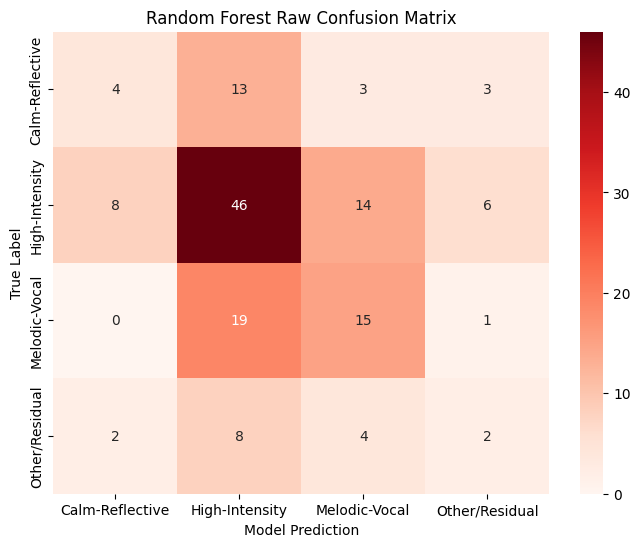

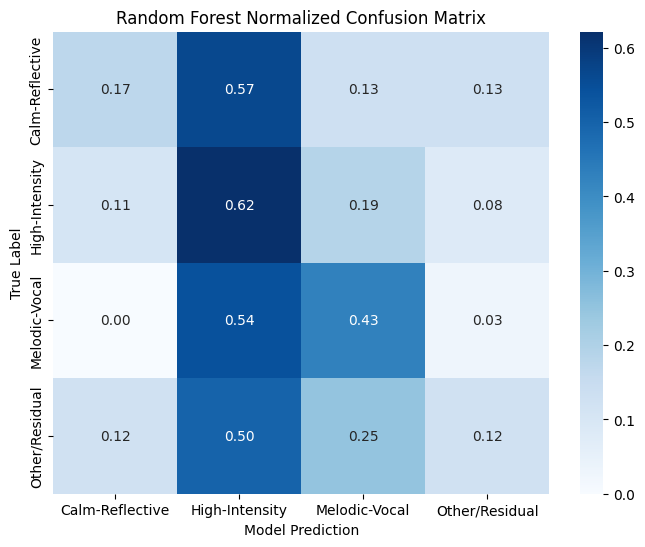

In [41]:
cm_raw = confusion_matrix(y_holdout, final_y_predictions)
cm_norm = confusion_matrix(y_holdout, final_y_predictions, normalize="true")

#Raw
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_raw,
    annot=True,
    fmt='d',
    cmap='Reds',
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)
plt.title(f'{winning_name} Raw Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Model Prediction')
plt.show()

#Normalized
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)

plt.title(f'{winning_name} Normalized Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Model Prediction')
plt.show()

In [42]:
n_bootstraps = 1000
bootstrapped_accuracies = []
bootstrapped_f1_scores = []

np.random.seed(42)

y_true = np.array(y_holdout)
y_pred = np.array(final_y_predictions)

for _ in range(n_bootstraps):

    indices = resample(np.arange(len(y_true)))
    y_true_boot = y_true[indices]
    y_pred_boot = y_pred[indices]

    acc = accuracy_score(y_true_boot, y_pred_boot)
    f1 = f1_score(y_true_boot, y_pred_boot, average='macro', zero_division=0)

    bootstrapped_accuracies.append(acc)
    bootstrapped_f1_scores.append(f1)

acc_lower = np.percentile(bootstrapped_accuracies, 2.5)
acc_upper = np.percentile(bootstrapped_accuracies, 97.5)

f1_lower = np.percentile(bootstrapped_f1_scores, 2.5)
f1_upper = np.percentile(bootstrapped_f1_scores, 97.5)

print("Bootstrap 95% Confidence Interval (Holdout Accuracy): [", acc_lower, ',', acc_upper, "]")
print("Bootstrap 95% Confidence Interval (Holdout Macro F1): [", f1_lower, "," , f1_upper, "]")

Bootstrap 95% Confidence Interval (Holdout Accuracy): [ 0.3714527027027027 , 0.5405405405405406 ]
Bootstrap 95% Confidence Interval (Holdout Macro F1): [ 0.2607676399436006 , 0.4237779663724093 ]


In [43]:
print("Stratified Baseline Accuracy:", accuracy_score(y_holdout, predictions_stratified_baseline))
print("Stratified Baseline Macro F1:", f1_score(y_holdout, predictions_stratified_baseline, average='macro', zero_division=0))
print("Stratified Baseline Balanced Accuracy:", balanced_accuracy_score(y_holdout, predictions_stratified_baseline))
print("\nClassification Report (Stratified Baseline):")
print(classification_report(y_holdout, predictions_stratified_baseline, target_names=target_encoder.classes_, zero_division=0))

y_true = np.array(y_holdout)
y_pred_model = np.array(final_y_predictions)
y_pred_baseline = np.array(predictions_stratified_baseline)

if y_pred_model.ndim > 1:
    y_pred_model = y_pred_model.flatten()
if y_pred_baseline.ndim > 1:
    y_pred_baseline = y_pred_baseline.flatten()

n_bootstraps = 1000
bootstrap_diffs = []

np.random.seed(42)
n_holdout = len(y_true)

for _ in range(n_bootstraps):
    indices = np.random.choice(n_holdout, size=n_holdout, replace=True)

    y_true_resampled = y_true[indices]
    model_resampled = y_pred_model[indices]
    baseline_resampled = y_pred_baseline[indices]

    score_model = f1_score(y_true_resampled, model_resampled, average='macro', zero_division=0)
    score_baseline = f1_score(y_true_resampled, baseline_resampled, average='macro', zero_division=0)

    bootstrap_diffs.append(score_model - score_baseline)

lower_bound_diff = np.percentile(bootstrap_diffs, 2.5)
upper_bound_diff = np.percentile(bootstrap_diffs, 97.5)

print("\nPaired Bootstrap 95% CI (Final Model - Stratified Macro F1 Difference): [", lower_bound_diff, ",", upper_bound_diff,"]")

Stratified Baseline Accuracy: 0.33783783783783783
Stratified Baseline Macro F1: 0.23613841737509117
Stratified Baseline Balanced Accuracy: 0.23744386855799898

Classification Report (Stratified Baseline):
                 precision    recall  f1-score   support

Calm-Reflective       0.19      0.22      0.20        23
 High-Intensity       0.53      0.53      0.53        74
  Melodic-Vocal       0.16      0.14      0.15        35
 Other/Residual       0.06      0.06      0.06        16

       accuracy                           0.34       148
      macro avg       0.24      0.24      0.24       148
   weighted avg       0.34      0.34      0.34       148


Paired Bootstrap 95% CI (Final Model - Stratified Macro F1 Difference): [ 5.352066747004538e-05 , 0.20559233471121455 ]


In [44]:
total_err_df = pd.DataFrame({'true_class': target_encoder.inverse_transform(y_holdout),
                            'predicted_class': target_encoder.inverse_transform(final_y_predictions)
                            })
total_err_df['confidence'] = final_model.predict_proba(X_holdout_C).max(axis=1)
total_err_df['correct'] = (total_err_df['true_class'] == total_err_df['predicted_class'])
error_pairs = (total_err_df.loc[~total_err_df['correct']].groupby(['true_class', 'predicted_class']).size().sort_values(ascending = False))
print("Most Common Error Pairs")
print(error_pairs.head(10))
print("\n\n")
print("Sample of predictions with confidence:")
print(total_err_df.head(10))

print("Avg Confidence: Correct vs Incorrect")
avg_conf_correct = total_err_df.loc[total_err_df['correct'], 'confidence'].mean()
avg_conf_incorrect = total_err_df.loc[~total_err_df['correct'], 'confidence'].mean()
print("Average Confidence (Correct):", avg_conf_correct)
print("Average Confidence (Incorrect):", avg_conf_incorrect)
print("\n")

Most Common Error Pairs
true_class       predicted_class
Melodic-Vocal    High-Intensity     19
High-Intensity   Melodic-Vocal      14
Calm-Reflective  High-Intensity     13
High-Intensity   Calm-Reflective     8
Other/Residual   High-Intensity      8
High-Intensity   Other/Residual      6
Other/Residual   Melodic-Vocal       4
Calm-Reflective  Other/Residual      3
                 Melodic-Vocal       3
Other/Residual   Calm-Reflective     2
dtype: int64



Sample of predictions with confidence:
        true_class predicted_class  confidence  correct
0    Melodic-Vocal  High-Intensity    0.443833    False
1   High-Intensity  High-Intensity    0.315552     True
2    Melodic-Vocal  High-Intensity    0.545929    False
3   High-Intensity  High-Intensity    0.578837     True
4   High-Intensity  High-Intensity    0.510687     True
5   Other/Residual  High-Intensity    0.464255    False
6   High-Intensity   Melodic-Vocal    0.406887    False
7  Calm-Reflective  High-Intensity    0.399900    